### Drehfreudig? – Lösung Schritt für Schritt

*44. Bundeswettbewerb Informatik (2025), 1. Runde, Aufgabe 1*

In der Informatik kann ein *Baum* so aufgebaut werden: Man beginnt mit einem *Knoten*, der *Wurzel*. Dann wird der Baum
wiederholt dadurch erweitert, dass unter einen vorhandenen Knoten u ein neuer Knoten gehängt wird, den man ein *Kind*
von u nennt. Wir zeichnen die Kinder eines Knotens von links nach rechts in der Reihenfolge, in der sie eingefügt wurden.
Ein Knoten ohne Kinder heißt *Blatt*.

Es ist leicht, einen gegebenen Baum durch ein großes Rechteck aus kleineren Rechtecken darzustellen: Jeder Knoten wird durch ein
Rechteck dargestellt, und für jeden Knoten u, der kein Blatt ist, gilt, dass die Rechtecke seiner Kinder die gleiche Breite haben
und die Vereinigung ihrer Oberseiten die Unterseite des Rechtecks von u ergibt.

Unter einer Zeichnung eines Baums mit der Wurzel oben kann man den Baum zusätzlich um 180° gedreht mit der Wurzel unten
zeichnen. Wenn man nun auch noch Rechtecke nach den obigen Regeln dazu zeichnet, kommt die Frage auf, ob erreicht werden
kann, dass sich die Blätter in der Mitte passgenau treffen, das heißt, dort dieselben Rechtecke benutzen.
Dann nennen wir den Baum *drehfreudig*.

#### Aufgabe 1

Schreibe ein Programm, das einen Baum einliest, herausfindet, ob er drehfreudig ist, und, falls ja, ein Bild ausgibt,
das seine Drehfreudigkeit zeigt.

Der Baum ist in der Eingabe in natürlicher Weise durch eine Folge von Klammern repräsentiert. Jeder Knoten entspricht einem
Klammerpaar; zwischen den Klammern sind die Kinder des Knotens angegeben. Zum Beispiel werden die nicht drehfreudigen Bäume auf dem
Aufgabenblatt durch die Folgen `((()())(()()()))` bzw. `((()())((()())()))` repräsentiert.

Wende dein Programm mindestens auf alle Beispiele an, die du auf den BWINF-Webseiten findest, und dokumentiere die Ergebnisse.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `drehfreudig01.txt` bis `drehfreudig15.txt`. Jede Datei enthält einen Baum als Klammerfolge, zum
Beispiel `(()())` für eine Wurzel mit zwei Kindern:

```
((()())(()()()))
```

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Baum und Klammerfolge:** Jede öffnende Klammer ist ein neuer Knoten, und der **Elternknoten** ist der Knoten, dessen Klammer
  gerade noch offen ist. Welche das ist, merkt man sich mit einem **Stapel** (*Stack*): Bei `(` legt man den Knoten oben auf den
  Stapel, bei `)` nimmt man den obersten wieder weg. Der oberste Knoten ist immer der gerade offene.
- **Breiten von oben nach unten:** Die Wurzel ist 1 breit. Hat ein Knoten `k` Kinder, bekommt jedes Kind `1/k` der Breite des
  Knotens. Man rechnet also von den Eltern zu den Kindern.
- **Brüche als Nenner speichern:** Jede Breite ist ein Bruch `1/Nenner`. Statt Kommazahlen speichern wir nur den Nenner (eine
  ganze Zahl). Dann gibt es keine Rundungsfehler beim Vergleichen.
- **Palindrom:** Eine Liste, die vorwärts und rückwärts gelesen gleich ist. Genau das ist die Bedingung für „drehfreudig“.
- **Zeichnen mit Rechtecken:** Jeder Knoten hat eine Position und eine Größe. Nach dem Drehen um 180° wird alles gespiegelt.

**Nützliche Funktionen und Bibliotheken**
- Listen als Stapel: `append` und `pop`, Umkehren einer Liste mit `liste[::-1]`
- `matplotlib.pyplot` und `matplotlib.patches.Rectangle` für die Zeichnung

## Die Idee

1. Die Klammerfolge **einmal von links nach rechts** lesen. Dabei merken wir uns für jeden Knoten seinen Elternknoten, seine Tiefe
   (Wurzel = 0) und die Zahl seiner Kinder.
2. Daraus die **Breite** jedes Knotens berechnen: Breite = Breite des Elternknotens geteilt durch die Zahl seiner Geschwister
   (einschließlich ihm selbst).
3. Die **Blätter** von links nach rechts aufschreiben. Dreht man den Baum um 180°, liegen sich das erste und das letzte Blatt
   gegenüber, das zweite und das vorletzte und so weiter. Sie passen genau, wenn sie gleich breit sind. Der Baum ist also
   **drehfreudig, wenn die Folge der Blattbreiten ein Palindrom ist.**
4. Bei einem drehfreudigen Baum den Baum und den gedrehten Baum **zeichnen**.

## Schritt 1: Die Klammerfolge lesen

Die Datei enthält eine einzige Zeile. Mit `.strip()` entfernen wir den Zeilenumbruch am Ende.

In [ ]:
def lies_baum(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        return f.read().strip()


klammern = lies_baum('beispieldaten/drehfreudig02.txt')
print(klammern)
print('Länge:', len(klammern))

((()())(()()()))
Länge: 16


## Schritt 2: Eltern, Kinder und Tiefe

Wir nummerieren die Knoten in der Reihenfolge, in der ihre öffnende Klammer vorkommt: Die Wurzel ist Knoten 0, der nächste Knoten
ist 1 und so weiter. Für jeden Knoten führen wir drei Listen (an Position `u` steht der Wert für Knoten `u`):

- `eltern[u]`: der Elternknoten (bei der Wurzel −1)
- `kinder[u]`: die Zahl der Kinder
- `tiefe[u]`: die Tiefe (Wurzel 0, ihre Kinder 1, …)

Dazu der **Stapel** `offen`: Er enthält die Knoten, deren Klammer gerade noch offen ist. Bei `(` ist der oberste Knoten des Stapels
der Elternknoten des neuen Knotens (ist der Stapel leer, ist es die Wurzel). Der neue Knoten wird dann oben aufgelegt. Bei `)`
nehmen wir den obersten Knoten vom Stapel, denn seine Klammer ist jetzt geschlossen.

Jedes Zeichen wird genau einmal angeschaut, das Einlesen ist also schnell, auch bei sehr langen Klammerfolgen.

In [ ]:
def lies_struktur(klammern):
    eltern = []
    kinder = []
    tiefe = []
    offen = []                                   # Stapel der Knoten mit noch offener Klammer
    for zeichen in klammern:
        if zeichen == '(':
            u = len(eltern)                      # Nummer des neuen Knotens
            if len(offen) > 0:
                v = offen[-1]                    # oberster Knoten des Stapels: der Elternknoten
                eltern.append(v)
                tiefe.append(tiefe[v] + 1)
                kinder[v] = kinder[v] + 1
            else:
                eltern.append(-1)                # die Wurzel
                tiefe.append(0)
            kinder.append(0)
            offen.append(u)
        else:
            offen.pop()
    return eltern, kinder, tiefe


eltern, kinder, tiefe = lies_struktur('(()())')
print('eltern:', eltern)
print('kinder:', kinder)
print('tiefe: ', tiefe)

eltern: [-1, 0, 0]
kinder: [2, 0, 0]
tiefe:  [0, 1, 1]


Zur Kontrolle der Baum `(()())`: Knoten 0 ist die Wurzel mit den Kindern 1 und 2 (beide haben Elternknoten 0 und Tiefe 1). Die
Knoten 1 und 2 haben keine Kinder, sind also Blätter.

## Schritt 3: Die Breiten

Die Wurzel ist 1 breit. Jedes Kind eines Knotens mit `k` Kindern ist `k`-mal schmaler als sein Elternknoten. Hat die Wurzel 3 Kinder
und eines davon wieder 2 Kinder, sind diese Enkel `1/3 / 2 = 1/6` breit.

Alle Breiten sind Brüche mit Zähler 1. Darum speichern wir nur den **Nenner**: `nenner[u]` ist 1 für die Wurzel und sonst
`nenner[eltern[u]] * kinder[eltern[u]]`. Dann rechnen wir nur mit ganzen Zahlen und vergleichen exakt.

Weil die öffnende Klammer eines Elternknotens immer vor denen seiner Kinder steht, hat ein Elternknoten eine kleinere Nummer als
seine Kinder. Geht man die Knoten **in der Reihenfolge ihrer Nummern** durch, ist der Nenner des Elternknotens immer schon bekannt.

In [ ]:
def berechne_nenner(eltern, kinder):
    nenner = []
    for u in range(len(eltern)):
        if eltern[u] == -1:
            nenner.append(1)
        else:
            v = eltern[u]
            nenner.append(nenner[v] * kinder[v])
    return nenner


klammern = lies_baum('beispieldaten/drehfreudig02.txt')
eltern, kinder, tiefe = lies_struktur(klammern)
nenner = berechne_nenner(eltern, kinder)
print(klammern)
print('nenner:', nenner)

((()())(()()()))
nenner: [1, 2, 4, 4, 2, 6, 6, 6]


Der Baum `((()())(()()()))` hat unter der Wurzel zwei Kinder mit Breite 1/2. Das linke hat 2 Kinder mit Breite 1/4, das rechte
3 Kinder mit Breite 1/6.

## Schritt 4: Die Blätter und das Palindrom

Die **Blätter** sind die Knoten ohne Kinder. Da wir die Knoten in der Reihenfolge der öffnenden Klammern nummeriert haben,
kommen die Blätter in `blaetter` automatisch **von links nach rechts**. Dann sammeln wir ihre Nenner in `blatt_nenner`.

Der Baum ist drehfreudig, wenn `blatt_nenner` rückwärts gelesen (`liste[::-1]`) genauso aussieht wie vorwärts. Sind die Nenner gleich, sind
auch die Breiten gleich, und dann passen die Blätter nach dem Drehen aufeinander.

In [ ]:
def finde_blaetter(kinder):
    blaetter = []
    for u in range(len(kinder)):
        if kinder[u] == 0:
            blaetter.append(u)
    return blaetter


def ist_drehfreudig(nenner, blaetter):
    blatt_nenner = []
    for u in blaetter:
        blatt_nenner.append(nenner[u])
    return blatt_nenner == blatt_nenner[::-1]


blaetter = finde_blaetter(kinder)
print('Blätter:', blaetter)
print('Nenner der Blätter:', [nenner[u] for u in blaetter])
print('drehfreudig:', ist_drehfreudig(nenner, blaetter))

Blätter: [2, 3, 5, 6, 7]
Nenner der Blätter: [4, 4, 6, 6, 6]
drehfreudig: False


Die Blattbreiten sind 1/4, 1/4, 1/6, 1/6, 1/6, rückwärts 1/6, 1/6, 1/6, 1/4, 1/4. Das ist **kein** Palindrom, der Baum ist nicht
drehfreudig. Das ist der erste nicht drehfreudige Baum vom Aufgabenblatt.

## Schritt 5: Alle Beispiele (nur die Entscheidung)

Wir fassen die Schritte in einer Funktion zusammen und lassen sie auf alle 15 Beispiele los.

In [ ]:
def untersuche(klammern):
    eltern, kinder, tiefe = lies_struktur(klammern)
    nenner = berechne_nenner(eltern, kinder)
    blaetter = finde_blaetter(kinder)
    return ist_drehfreudig(nenner, blaetter), len(eltern), len(blaetter)


ergebnisse = {}
for nr in range(1, 16):
    klammern = lies_baum('beispieldaten/drehfreudig' + str(nr).rjust(2, '0') + '.txt')
    drehfreudig, knoten, blaetter = untersuche(klammern)
    ergebnisse[nr] = drehfreudig
    if drehfreudig:
        text = 'drehfreudig'
    else:
        text = 'nicht drehfreudig'
    print('drehfreudig' + str(nr).rjust(2, '0') + '.txt:', str(knoten).rjust(3), 'Knoten,', str(blaetter).rjust(2), 'Blätter:', text)

drehfreudig01.txt:  27 Knoten, 16 Blätter: drehfreudig
drehfreudig02.txt:   8 Knoten,  5 Blätter: nicht drehfreudig
drehfreudig03.txt:   9 Knoten,  5 Blätter: nicht drehfreudig
drehfreudig04.txt:   9 Knoten,  6 Blätter: drehfreudig
drehfreudig05.txt:  13 Knoten,  9 Blätter: nicht drehfreudig
drehfreudig06.txt:  18 Knoten, 12 Blätter: drehfreudig
drehfreudig07.txt:  18 Knoten,  9 Blätter: nicht drehfreudig
drehfreudig08.txt:  32 Knoten, 21 Blätter: drehfreudig
drehfreudig09.txt:  31 Knoten, 19 Blätter: nicht drehfreudig
drehfreudig10.txt:  58 Knoten, 39 Blätter: drehfreudig
drehfreudig11.txt:  27 Knoten, 13 Blätter: nicht drehfreudig
drehfreudig12.txt:  57 Knoten, 38 Blätter: nicht drehfreudig
drehfreudig13.txt:  97 Knoten, 72 Blätter: drehfreudig
drehfreudig14.txt:  37 Knoten, 25 Blätter: nicht drehfreudig
drehfreudig15.txt:  21 Knoten, 14 Blätter: drehfreudig


Sieben der fünfzehn Bäume sind drehfreudig: 01, 04, 06, 08, 10, 13 und 15. Das stimmt mit den offiziellen Lösungshinweisen überein.

## Schritt 6: Die Zeichnung

Für ein Bild brauchen wir für jeden Knoten ein Rechteck. Die **Breite** ist `1 / nenner[u]`. Die **linke Kante** `x[u]` bestimmen wir
auch beim Durchgehen der Knoten in ihrer Nummerierung: Das erste Kind eines Knotens beginnt bei der linken Kante des Elternknotens,
jedes weitere genau dort, wo sein linker Nachbar aufhört. Dafür merken wir uns in `naechstes[v]`, wo das nächste Kind von `v` anfängt.

Die **Höhe** ist 1 für jeden Knoten, der kein Blatt ist, und `maximale Tiefe + 1 − Tiefe` für ein Blatt: Ein Blatt reicht bis ganz
nach unten. Alle Blätter enden dann auf derselben Linie, und dort treffen sich der Baum und der gedrehte Baum.

Den **gedrehten Baum** zeichnen wir darunter: Alles wird um 180° gedreht, also von links nach rechts **und** von oben nach unten
gespiegelt. Bei `x` wird aus der linken Kante `x` und der Breite `b` die neue linke Kante `1 − x − b`. Die Blätter liegen
dann aufeinander, wenn die Breiten ein Palindrom bilden.

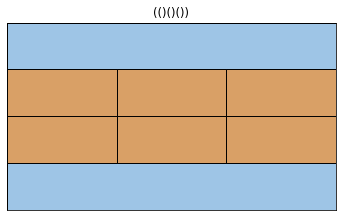

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def berechne_positionen(eltern, kinder, nenner):
    """Linke Kante x[u] jedes Knotens (Wurzel: 0, Gesamtbreite 1)."""
    x = []
    naechstes = []                                   # naechstes[v]: wo das nächste Kind von v anfängt
    for u in range(len(eltern)):
        if eltern[u] == -1:
            x.append(0)
        else:
            x.append(naechstes[eltern[u]])
            naechstes[eltern[u]] = naechstes[eltern[u]] + 1 / nenner[u]
        naechstes.append(x[u])                       # das erste Kind beginnt links beim Elternknoten
    return x


def zeichne(klammern, achse, titel):
    eltern, kinder, tiefe = lies_struktur(klammern)
    nenner = berechne_nenner(eltern, kinder)
    x = berechne_positionen(eltern, kinder, nenner)
    hoehe_baum = max(tiefe) + 1                      # Zahl der Ebenen
    for u in range(len(eltern)):
        breite = 1 / nenner[u]
        if kinder[u] == 0:
            hoehe = hoehe_baum - tiefe[u]            # Blätter reichen bis nach unten
            farbe = '#d9a066'
        else:
            hoehe = 1
            farbe = '#9ec5e6'
        oben = tiefe[u]
        # Baum mit der Wurzel oben (die y-Achse zeigt nach unten)
        achse.add_patch(Rectangle((x[u], oben), breite, hoehe, facecolor=farbe, edgecolor='black'))
        # um 180 Grad gedrehter Baum darunter: x und y spiegeln
        achse.add_patch(Rectangle((1 - x[u] - breite, 2 * hoehe_baum - oben - hoehe), breite, hoehe,
                                  facecolor=farbe, edgecolor='black'))
    achse.set_xlim(0, 1)
    achse.set_ylim(2 * hoehe_baum, 0)
    achse.set_title(titel)
    achse.set_xticks([])
    achse.set_yticks([])


fig, achse = plt.subplots(figsize=(5, 3.2))
zeichne('(()()())', achse, '(()()())')
plt.tight_layout()
plt.show()

Oben steht der Baum mit der Wurzel oben, unten derselbe Baum um 180° gedreht. Die Blätter (orange) liegen in der Mitte genau
aufeinander. Die Wurzel hat hier 3 Kinder gleicher Breite, die Zeichnung ist daher spiegelsymmetrisch.

## Schritt 7: Alle drehfreudigen Beispiele als Bild

Jetzt zeichnen wir alle Bäume, die drehfreudig sind. Bei den größeren Bäumen sind die Rechtecke sehr schmal.

Gezeichnet: [1, 4, 6, 8, 10, 13, 15]


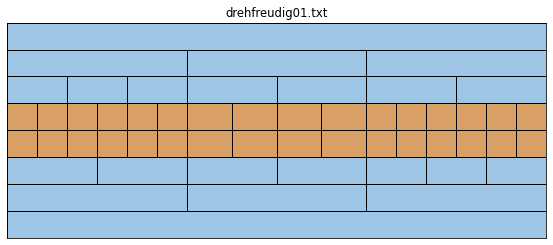

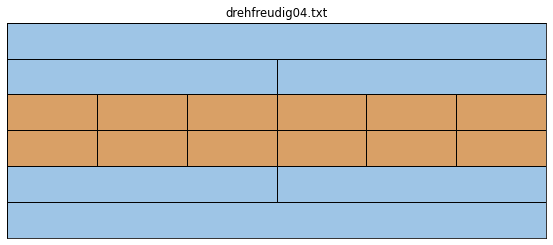

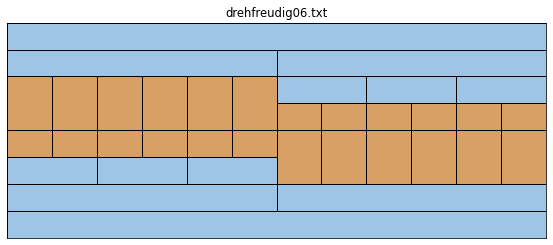

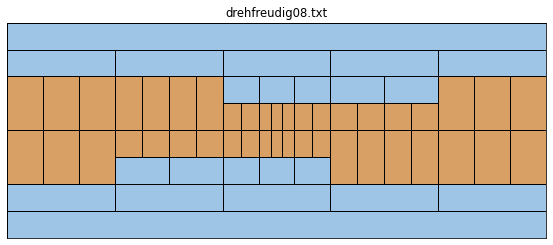

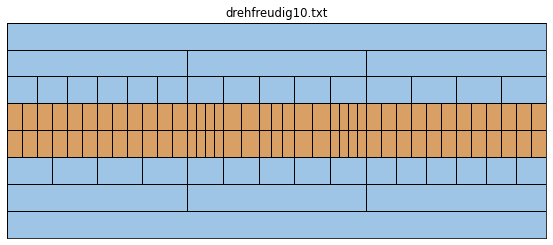

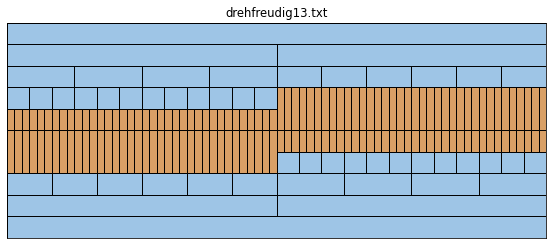

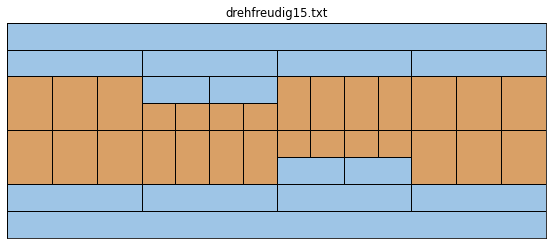

In [ ]:
nummern = []
for nr in range(1, 16):
    if ergebnisse[nr]:
        nummern.append(nr)

for nr in nummern:
    klammern = lies_baum('beispieldaten/drehfreudig' + str(nr).rjust(2, '0') + '.txt')
    fig, achse = plt.subplots(figsize=(8, 3.6))
    zeichne(klammern, achse, 'drehfreudig' + str(nr).rjust(2, '0') + '.txt')
    plt.tight_layout()
    plt.show()
print('Gezeichnet:', nummern)

**Ergebnis:** Die Beispiele 01, 04, 06, 08, 10, 13 und 15 sind drehfreudig, alle anderen nicht. Bei `drehfreudig06.txt`,
`drehfreudig08.txt`, `drehfreudig13.txt` und `drehfreudig15.txt` sieht man in der Mitte, dass Blätter, die genau aufeinander
liegen, **verschieden hoch** sind. Die Breiten passen, die Höhen nicht. Bei der Aufgabe zählt nur die Breite, deshalb sind
sie drehfreudig (siehe „Für Neugierige“).

## Für Neugierige

**Eine strengere Definition:** Die Lösungshinweise erlauben auch, dass nicht nur die **Breiten**, sondern auch die **Höhen** der
Blätter übereinstimmen müssen, also dass auch die Tiefen der Blätter ein Palindrom bilden. Dann sind die Beispiele 06, 08, 13 und
15 zusätzlich nicht drehfreudig. Dafür muss man nur die Tiefen der Blätter mit prüfen:

In [ ]:
def ist_streng_drehfreudig(nenner, blaetter, tiefe):
    blatt_nenner = []
    blatt_tiefe = []
    for u in blaetter:
        blatt_nenner.append(nenner[u])
        blatt_tiefe.append(tiefe[u])
    return blatt_nenner == blatt_nenner[::-1] and blatt_tiefe == blatt_tiefe[::-1]


for nr in range(1, 16):
    klammern = lies_baum('beispieldaten/drehfreudig' + str(nr).rjust(2, '0') + '.txt')
    eltern, kinder, tiefe = lies_struktur(klammern)
    nenner = berechne_nenner(eltern, kinder)
    blaetter = finde_blaetter(kinder)
    streng = ist_streng_drehfreudig(nenner, blaetter, tiefe)
    if ergebnisse[nr] and not streng:
        print('drehfreudig' + str(nr).rjust(2, '0') + '.txt: nur bei gleichen Breiten drehfreudig')

drehfreudig06.txt: nur bei gleichen Breiten drehfreudig
drehfreudig08.txt: nur bei gleichen Breiten drehfreudig
drehfreudig13.txt: nur bei gleichen Breiten drehfreudig
drehfreudig15.txt: nur bei gleichen Breiten drehfreudig


**Andere Ideen, die nicht immer klappen:** Symmetrie der Klammerfolge (gleich vorwärts und rückwärts, wenn man `(` und `)`
vertauscht) ist **nicht** dasselbe wie drehfreudig: Ein Baum kann spiegelsymmetrisch sein, ohne dass die Blattbreiten ein Palindrom
bilden, und umgekehrt. Die Lösungshinweise warnen ausdrücklich davor. Das Palindrom der Blattbreiten ist das richtige Kriterium.

**Ausgabe als Text:** Statt eines Bildes kann man den Baum auch mit Zeichen ausgeben. Dafür multipliziert man alle Breiten mit
dem **kleinsten gemeinsamen Vielfachen (kgV)** aller Nenner der Blätter, damit jede Breite eine ganze Zahl von Zeichen wird.
In Python gibt es dafür `math.lcm`.

**Laufzeit:** Jedes Zeichen der Klammerfolge wird einmal gelesen, danach geht man alle Knoten einmal durch. Das Verfahren braucht
also nur so viele Schritte wie die Eingabe lang ist, auch für sehr große Bäume. Die Nenner können dabei allerdings sehr große
Zahlen werden, mit denen Python aber problemlos rechnen kann.